# Độ bền PhoWhisper-small khi audio bị nhiễu

Đo trên 857 bản FLEURS test. Mỗi điều kiện đổi đúng một yếu tố so với bản gốc: nhiễu trắng theo SNR, tốc độ (resample), âm lượng.

Đây chỉ là bài đo độ bền. Khối nghe **không** được fine-tune, kết quả **không** dùng để chọn mô hình. Nhiễu tất định theo id bản thu, seed 42. Chấm bằng `score_asr.py`, cùng protocol ASR.

Chạy lại: `bash scripts/hang_doi_robust.sh` (cần GPU và `data/`).

## 1. Cách sinh audio nhiễu

In [1]:
from pathlib import Path
T = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print((T / "scripts/asr/tao_audio_robust.py").read_text(encoding="utf-8"))

#!/usr/bin/env python3
"""Sinh audio nhiễu để đo độ bền PhoWhisper trên FLEURS test (chỉ benchmark, KHÔNG fine-tune ASR, không dùng để chọn model).

Mỗi điều kiện thay đúng một yếu tố so với bản gốc: thêm nhiễu trắng theo SNR, đổi tốc độ (resample, cao độ đổi theo), đổi âm lượng.
Nhiễu tất định theo id (seed = SHA256 của "42:điều_kiện:id"). Ghi runs/robust/audio/<điều_kiện>/*.wav và runs/robust/manifests/<điều_kiện>.jsonl.
Chạy: $P scripts/asr/tao_audio_robust.py <điều_kiện>   (không đối số: tất cả)
"""
import hashlib
import json
import sys
from fractions import Fraction
from pathlib import Path

import numpy as np
import soundfile as sf
from scipy.signal import resample_poly

T = Path(__file__).resolve().parents[2]
SR = 16000
DIEU_KIEN = {"noise_snr20": ("noise", 20), "noise_snr10": ("noise", 10), "speed_0.9": ("speed", 0.9), "speed_1.1": ("speed", 1.1), "vol_-12dB": ("gain", -12)}


def bien_doi(a, kieu, gt, rid):
    if kieu == "noise":
        rng = np.random.default_rng(int(hashli

## 2. Kết quả

In [2]:
import json
import pandas as pd
goc = json.loads((T / "runs/asr/kiet_t2_phowhisper-small_fleurs_test/score/summary.json").read_text(encoding="utf-8"))
dk = [("noise_snr20", "nhiễu trắng SNR 20 dB"), ("noise_snr10", "nhiễu trắng SNR 10 dB"), ("speed_0.9", "chậm lại 0,9 lần"), ("speed_1.1", "nhanh lên 1,1 lần"), ("vol_-12dB", "giảm âm lượng 12 dB")]
R = [dict(dieu_kien="goc", mo_ta="bản gốc", n=goc["n"], WER=goc["WER_percent"], CER=goc["CER_percent"], chenh_WER=0.0)]
for k, v in dk:
    s = json.loads((T / f"runs/robust/robust_pho_{k}/score/summary.json").read_text(encoding="utf-8"))
    R.append(dict(dieu_kien=k, mo_ta=v, n=s["n"], WER=s["WER_percent"], CER=s["CER_percent"], chenh_WER=round(s["WER_percent"] - goc["WER_percent"], 2)))
B = pd.DataFrame(R); (T / "reports/robust").mkdir(exist_ok=True); B.to_csv(T / "reports/robust/bang_robust.csv", index=False, encoding="utf-8-sig"); B

,dieu_kien,mo_ta,n,WER,CER,chenh_WER
0,goc,bản gốc,857,13.677414,9.876474,0.00
1,noise_snr20,nhiễu trắng SNR 20 dB,857,15.322240,10.292690,1.64
2,noise_snr10,nhiễu trắng SNR 10 dB,857,17.017025,12.110425,3.34
3,speed_0.9,"chậm lại 0,9 lần",857,15.499020,9.876474,1.82
4,speed_1.1,"nhanh lên 1,1 lần",857,14.303832,10.992334,0.63
5,vol_-12dB,giảm âm lượng 12 dB,857,16.379078,11.127353,2.70


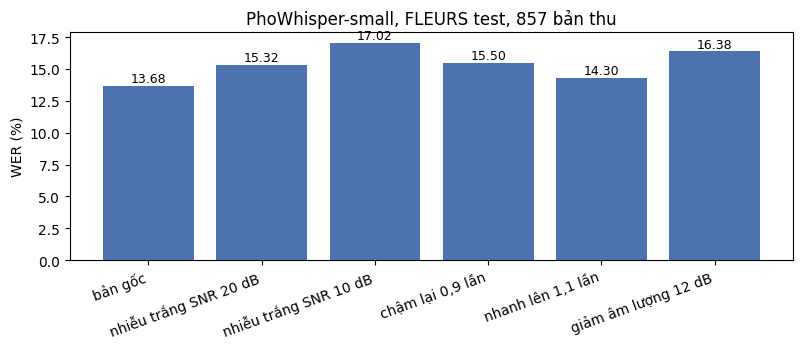

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.bar(B.mo_ta, B.WER, color="#4c72b0")
for i, v in enumerate(B.WER):
    ax.text(i, v + .3, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("WER (%)"); ax.set_title("PhoWhisper-small, FLEURS test, 857 bản thu"); plt.xticks(rotation=20, ha="right"); plt.tight_layout(); fig.savefig(T / "reports/robust/bang_robust.png", dpi=150); plt.show()

## 3. Giới hạn

Nhiễu trắng và đổi tốc độ bằng resample không phải tiếng ồn lớp học hay micro thật. Số ở đây chỉ cho biết xu hướng. Câu hỏi hệ chạy thế nào ngoài dataset vẫn cần bộ audio tự thu (`tests/bo_cau_tu_thu/`, NOT RUN).